# 2. Feature engineering

The first version of this project used 17 hand-picked columns. Here we add, one group at a time:

1. **All application columns** (categoricals are handled natively by CatBoost). Gender is left out on purpose: it is a protected attribute in lending.
2. **Engineered ratios and fixes** built from the application.
3. **Credit history** aggregated per customer from the `bureau`, `installments_payments` and `credit_card_balance` tables.

Everything here is computed on the **training set only** when we look at relationships with the target.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import features as F

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

import experiments as E
app = F.load_application()
train, valid, test = F.make_splits(app)
train = train.reset_index(drop=True)

## Engineered application features

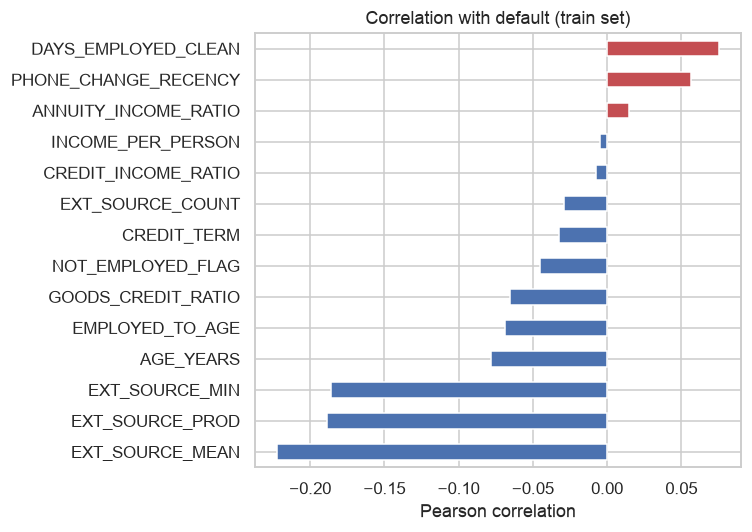

In [2]:
eng = F.engineered_features(train)
eng["TARGET"] = train["TARGET"].values
corr = eng.drop(columns="SK_ID_CURR").corr(numeric_only=True)["TARGET"].drop("TARGET").sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
corr.plot.barh(ax=ax, color=["#c44e52" if v > 0 else "#4c72b0" for v in corr])
ax.set_title("Correlation with default (train set)"); ax.set_xlabel("Pearson correlation")
plt.tight_layout(); plt.savefig("../reports/engineered_correlations.png"); plt.show()

The `EXT_SOURCE` combinations are by far the strongest linear signals. The ratios look weak here (correlation near zero), but a linear correlation can hide a non-linear pattern, so we look at the shape of two of them: the best score-based feature and the credit term (credit amount / annuity), which turns out to matter a lot in the final model.

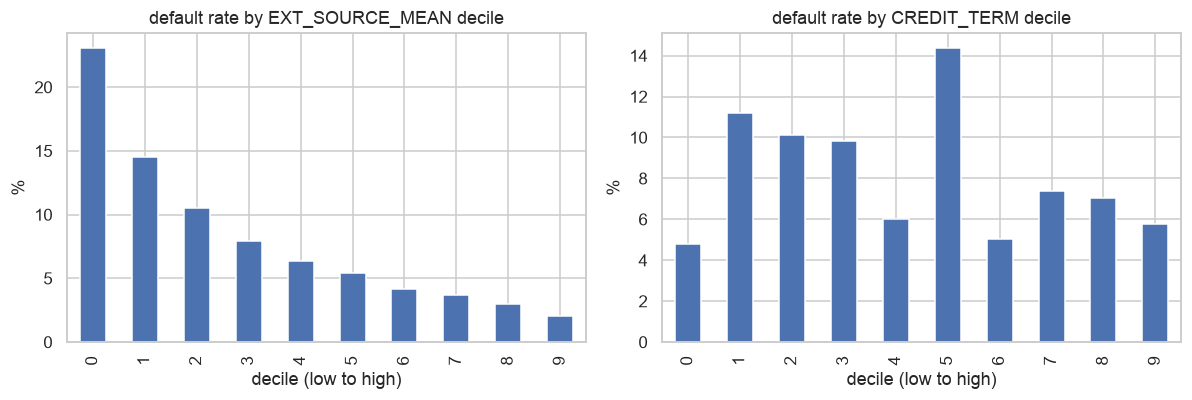

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col in zip(axes, ["EXT_SOURCE_MEAN", "CREDIT_TERM"]):
    deciles = pd.qcut(eng[col], 10, duplicates="drop")
    eng.groupby(deciles, observed=True)["TARGET"].mean().mul(100).reset_index(drop=True).plot.bar(ax=ax, color="#4c72b0")
    ax.set_title(f"default rate by {col} decile"); ax.set_xlabel("decile (low to high)"); ax.set_ylabel("%")
plt.tight_layout(); plt.show()

## Credit history from the other tables

Each customer can have many earlier loans. We summarise them into one row per customer (counts, averages, worst case, recent behaviour). The slow aggregations are cached in `data/cache/`.

In [4]:
hist = F.history_features(train["SK_ID_CURR"])
hist["TARGET"] = train["TARGET"].values
cover = pd.Series({
    "bureau records": hist["BUREAU_N_CREDITS"].notna().mean(),
    "installment history": hist["INST_COUNT"].notna().mean(),
    "credit card history": hist["CC_MONTHS"].notna().mean(),
})
print((cover * 100).round(1).astype(str).add("%").to_string())

bureau records         85.7%
installment history    94.7%
credit card history    28.1%


In [5]:
late = pd.cut(hist["INST_LATE_SHARE"], [-0.001, 0, 0.1, 0.25, 0.5, 1.0],
              labels=["never late", "0-10%", "10-25%", "25-50%", ">50%"])
rates = hist.groupby(late, observed=True)["TARGET"].agg(["mean", "size"])
rates["mean"] = (rates["mean"] * 100).round(2)
rates.columns = ["default rate (%)", "customers"]
rates

,default rate (%),customers
INST_LATE_SHARE,,
never late,6.83,109236
0-10%,7.79,59540
10-25%,9.97,43647
25-50%,12.45,18720
>50%,16.11,1813


Customers who have paid previous installments late are noticeably more likely to default now, which is exactly the signal the application form cannot provide. Missing history (new customers) is left as missing: tree models treat "no history" as information in its own right.

**Leakage check.** All of these are computed from a customer's *previous* loans and contain nothing derived from `TARGET`. The test set's history is aggregated with the same code and never influences any fitted value.

In [6]:
X_all, cats = E.build_stage(train.head(2000), "S4")
print(f"Final feature matrix: {X_all.shape[1]} features ({len(cats)} categorical)")

Final feature matrix: 156 features (15 categorical)
